# Postal Address City Extraction

This notebook crops the recipient label, reads it with Tesseract, and extracts only the most likely city using pattern and fuzzy matching. No LLM, CSV, or database is used.

In [197]:
%pip install opencv-python pillow matplotlib pytesseract pandas numpy

Note: you may need to restart the kernel to use updated packages.


In [198]:
from pathlib import Path
import re
from difflib import SequenceMatcher
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pytesseract
from PIL import Image

TESSERACT_PATH = Path(r'C:\Program Files\Tesseract-OCR\tesseract.exe')
if TESSERACT_PATH.exists():
    pytesseract.pytesseract.tesseract_cmd = str(TESSERACT_PATH)
LANGUAGES = pytesseract.get_languages(config='')
OCR_LANG = 'eng+sin' if 'sin' in LANGUAGES else 'eng'
print('OCR language:', OCR_LANG)

OCR language: eng+sin


In [199]:
CITY_CANDIDATES = [
    'Colombo', 'Dehiwala-Mount Lavinia', 'Galkissa', 'Moratuwa', 'Negombo',
    'Pita Kotte', 'Sri Jayewardenepura Kotte', 'Katunayaka', 'Battaramulla South',
    'Maharagama', 'Kotikawatta', 'Kolonnawa', 'Hendala', 'Welisara', 'Kalutara',
    'Homagama', 'Beruwala', 'Panadura', 'Mulleriyawa', 'Kandana', 'Ja Ela',
    'Wattala', 'Peliyagoda', 'Kelaniya', 'Hanwella Ihala', 'Gampaha',
    'Horana South', 'Minuwangoda', 'Horawala Junction'
]

In [200]:
def show_image(image, title='', cmap=None, figsize=(12, 7)):
    display_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB) if len(image.shape) == 3 else image
    plt.figure(figsize=figsize)
    plt.imshow(display_image, cmap=cmap)
    plt.title(title)
    plt.axis('off')
    plt.show()

def preprocess_image(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if len(image.shape) == 3 else image.copy()
    gray = cv2.bilateralFilter(gray, 7, 50, 50)
    return cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray)

def enhance_for_ocr(image, scale=3):
    enlarged = cv2.resize(image, None, fx=scale, fy=scale, interpolation=cv2.INTER_CUBIC)
    return cv2.cvtColor(cv2.detailEnhance(cv2.cvtColor(enlarged, cv2.COLOR_GRAY2BGR), sigma_s=10, sigma_r=0.15), cv2.COLOR_BGR2GRAY)

def crop_relative(image, x1=0.34, y1=0.36, x2=0.69, y2=0.66):
    h, w = image.shape[:2]
    return image[int(h*y1):int(h*y2), int(w*x1):int(w*x2)]

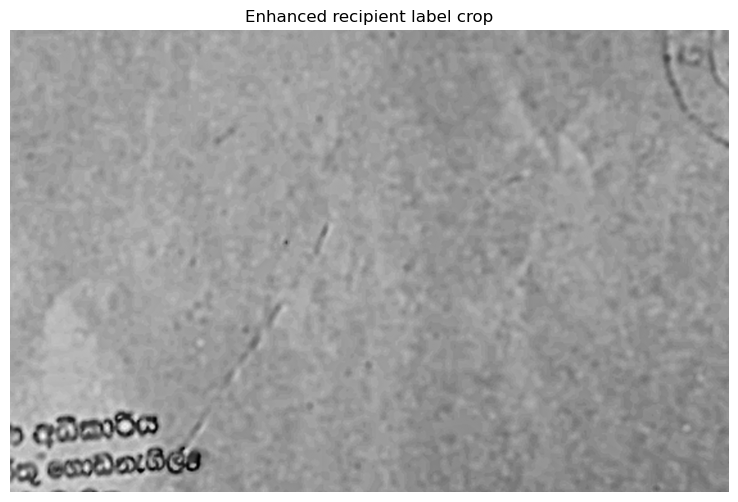

In [201]:
IMAGE_PATH = Path('./test/8.jpeg')
image = cv2.imread(str(IMAGE_PATH))
if image is None:
    raise FileNotFoundError(IMAGE_PATH)
processed = preprocess_image(image)
address_crop = enhance_for_ocr(crop_relative(processed))
show_image(address_crop, 'Enhanced recipient label crop', cmap='gray', figsize=(12, 6))

In [202]:
def read_all_orientations(crop):
    results = {}
    pil_crop = Image.fromarray(crop)
    for angle in (0, 90, 180, 270):
        rotated = pil_crop.rotate(angle, expand=True)
        text = pytesseract.image_to_string(rotated, lang=OCR_LANG, config='--psm 6')
        results[angle] = text
        print(f'\nROTATION: {angle} degrees')
        print('-' * 45)
        print(text.strip() or '[no text detected]')
    return results

rotation_results = read_all_orientations(address_crop)


ROTATION: 0 degrees
---------------------------------------------
"24% ₹ෘ ී 9. “ඒ. £* 419%: 9 iy | 042 '
OCS 6ෑ = a ‘ * 7. | Bins 7 a by? මූ %ඉ - |
රෑ 3 * ල්‌ 10 3111. 2 ඇමේ 7 ₹ (6 42. A | a *
Spr මල alee el Lea
07 ම $7 - 04 7 Tu 4 සි... 4 ම. ॥! 10.
43." ry 8. D> = on fh (4 oe wl .. ද. ඇම්‌
a a * > : -...... (0. > ee 1 E
. ory a ave” 1. 6d අං? "දද රූ
pe 4 ; ණ 4 මු 1” , "' ! 4 an
॥ 1 ව [| . 4 4 2. a or oF py: ow q , 145
ෂ ba) a r ~, ee ඨෲ ¥ 2 9 il ' : ia
*& a ක 2! ගී. දල ය්‌ 1

ROTATION: 90 degrees
---------------------------------------------
a 24 7 ම > ॥ ශේ ee න්‌ ඹ්‌ ‘
4 ed ඈ A p>) Pe °° a ~ =
\, Whee os, 1” pm # pt Said
‘Alp _ 4", * න P< 5305. 24053
ae අඳ 1:
ශ්‌ ඈ 2 re wei ¢ “
රන ewe ~ p< am tee
Z =. = ක __ 1 නූ $ * >
ණක ලෟ. - % & 4 03"~"5
¥ a ‘> ye. oP on (=a. ල්‌ । කී
4 1 x ao ae ap a," a rae * ඞී ය
4 4 ty 4 දී 2 . er) ere
රන්න 42-40 ඇ෴ 5:07. 1).
220 ; trey . a
rf , % i waa යම. ට, ද්‌ om
॥ . ව. "ම. ද
a wD Py 2: 4... - re දි
ත්‌ 2
a Se a
m wn 4 a 4 J pa දී
22a 5 ' a ¢ +
| o « ය 1)

In [203]:
def normalize_text(text):
    text = text.upper()
    replacements = {'0':'O', '1':'I', '|':'I', '5':'S'}
    return re.sub(r'\s+', ' ', ''.join(replacements.get(c, c) for c in text))

def city_match(text, candidates):
    normalized = normalize_text(text)
    scores = []
    for city in candidates:
        target = normalize_text(city)
        if re.search(r'\b' + re.escape(target) + r'\b', normalized):
            scores.append((1.0, city))
            continue
        # Compare each OCR word and short phrase with the candidate.
        words = re.findall(r'[A-Z]+', normalized)
        best = max((SequenceMatcher(None, target, word).ratio() for word in words), default=0)
        scores.append((best, city))
    return max(scores, key=lambda x: x[0])

rotation_city_results = []
for angle, text in rotation_results.items():
    confidence, city = city_match(text, CITY_CANDIDATES)
    rotation_city_results.append((confidence, city, angle, text))
confidence, city, best_angle, ocr_text = max(rotation_city_results, key=lambda item: item[0])
print('\nFINAL CITY')
print('==========')
if confidence >= 0.72:
    print(city)
    print(f'Confidence: {confidence:.2f}')
    print('Needs review:', confidence < 0.85)
else:
    print('No reliable city found')
    print(f'Best candidate: {city} ({confidence:.2f})')
    print('Needs review: True')


FINAL CITY
No reliable city found
Best candidate: Wattala (0.60)
Needs review: True
